<a href="https://colab.research.google.com/github/MelisaYasak/transformer_arch/blob/main/sherlockGPT_biagram_to_transformer_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Biagram'dan Self Attention'a

### Hatırlatma! Biagram Kısıtı
Bu örnekte the ve she yalnızca Bigram'ın sınırlılığını göstermek için seçildi. İki bağlamın mutlaka farklı sonraki karakter dağılımlarına sahip olması gerektiğini iddia etmiyoruz.

Bu deneyin öğrettiği: Bigram, önceki karakterlerden yararlanarak tahminini değiştiremiyor.

In [4]:
%run ./sherlockGPT_biagram_language_model.ipynb

[WinError 3] Sistem belirtilen yolu bulamıyor: '/content/drive/MyDrive/transformers'
d:\transformer_arch
Karakter sayısı: 562202
The Adventures of Sherlock Holmes

by Arthur Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   III.   A Case of Identity
   IV.    The Boscombe Valley Mystery
   V.     The Five Orange Pips
   VI.    The Man with the Twisted Lip
   VII.   The Adventure of the 


d:\transformer_arch\venv\Lib\site-packages\torch\_subclasses\functional_tensor.py:377: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:82.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


Vocabulary size: 88
Train shape: torch.Size([505981])
Validation shape: torch.Size([56221])
İlk karakterler: The Adventures of Sherlock Holmes

by Arthur Conan
Input shape: torch.Size([16, 8])
Target shape: torch.Size([16, 8])
Input: : It was
Target:  It was.
Başlangıç loss: 4.953321933746338
Step 0 | Train batch loss: 5.1560
Step 200 | Train batch loss: 4.8816
Step 400 | Train batch loss: 4.6854
Step 600 | Train batch loss: 4.4502
Step 800 | Train batch loss: 4.2775
Step 1000 | Train batch loss: 4.0147
Step 1200 | Train batch loss: 3.9220
Step 1400 | Train batch loss: 3.7821
Step 1600 | Train batch loss: 3.5867
Step 1800 | Train batch loss: 3.6534
Step 2000 | Train batch loss: 3.5122
Step 2200 | Train batch loss: 3.4434
Step 2400 | Train batch loss: 3.2040
Step 2600 | Train batch loss: 3.1138
Step 2800 | Train batch loss: 2.9315
Step 3000 | Train batch loss: 2.9604
Step 3200 | Train batch loss: 2.8752
Step 3400 | Train batch loss: 2.8289
Step 3600 | Train batch loss: 2.7359
Step 3800 

In [ ]:
import torch
import torch.nn.functional as F

model.eval()

with torch.no_grad():
    x1 = torch.tensor([encode("the")])
    x2 = torch.tensor([encode("she")])

    logits1, _ = model(x1)
    logits2, _ = model(x2)

    p1 = F.softmax(logits1[0, -1], dim=-1)
    p2 = F.softmax(logits2[0, -1], dim=-1)

    print("Aynı dağılım mı?", torch.allclose(p1, p2))
    print("En büyük fark:", (p1 - p2).abs().max().item())

Aynı dağılım mı? True
En büyük fark: 0.0


## Transformer mantığı

Burada mimari bir token için temsil oluştururken önceki tokenlardan bilgi toplayabiliyor. Bunu causal self-attention ile yapıyor.

Bir önceki örnekteki 'the' kelimesini ele alırsak; eğer e yi tahin etmesi gerekirse 't' ve 'h' karakterlerinin bilgisini de kullanacaktı.


### Embedding

Biagramda embeddingleri her karakter için doğrudan tüm olası sonraki karakterlerin logitlerini üretmek için kullandık.

Transformerda ise embedding vektörü öğrenilebilir temsil (ağırlık) olacak.

In [6]:
import torch
import torch.nn as nn


In [7]:
torch.manual_seed(42)

n_embed = 4

In [8]:
token_embedding = nn.Embedding(
    num_embeddings=vocab_size,
    embedding_dim=n_embed
)

In [9]:
x1 = torch.tensor([encode("the")])
x2 = torch.tensor([encode("she")])

In [10]:
emb1 = token_embedding(x1)
emb2 = token_embedding(x2)

In [11]:
print("Girdi boyutu (Input shape): ", x1.shape)
print("Embedding boyutu (Embedding shape): ", emb1.shape)

Girdi boyutu (Input shape):  torch.Size([1, 3])
Embedding boyutu (Embedding shape):  torch.Size([1, 3, 4])


Embedding boyutu (Embedding shape):  torch.Size([1, 3, 4])

Shape'i açıklamak gerekirse:


(batch içinde bir metin örneği var, üç karakter var, her karakter dört boyutlu bir embedding vektörü ile temsil ediliyor)

In [12]:
print("the - son token embedding: ", emb1[0,-1])
print("she - son token embedding: ", emb2[0,-1])

the - son token embedding:  tensor([ 0.1543,  0.4408, -0.1483, -2.3184], grad_fn=<SelectBackward0>)
she - son token embedding:  tensor([ 0.1543,  0.4408, -0.1483, -2.3184], grad_fn=<SelectBackward0>)


In [13]:
print("Aynı mı?")
print(torch.allclose(
    emb1[0, -1],
    emb2[0, -1]
))

Aynı mı?
True


Şu anlık ikiside aynı çünkü ikisinde de son karakter 'e' Yani token embedding tek başına bağlamı anlamıyor.

### Self-attention

Context aggregation:

Yeni bir karakter tahin ederken eski karakterleri dikkate almak istiyorsak bunu nasıl yapabiliriz?

En basit istatistiki yöntemi deneyelim. Ortalamasını almak.

In [14]:
# Her dizinin karakter embedding'lerini ortala
context1 = emb1.mean(dim=1)
context2 = emb2.mean(dim=1)

In [15]:
print("the context:", context1)
print("she context:", context2)

the context: tensor([[-0.4098,  0.9111, -0.8598, -1.1342]], grad_fn=<MeanBackward1>)
she context: tensor([[ 0.4852,  0.7847, -0.6573, -1.1203]], grad_fn=<MeanBackward1>)


In [16]:
print("Aynı mı?", torch.allclose(
    context1, context2
))

Aynı mı? False


Aynı değil çünkü 'e' tokenından önceki tokenlar farklı. Ama ya kelimler 'the' ve 'hte' olsaydı ne olacaktı?

Bu iki metin aynı karakterlerden oluştuğundan aynı ortalama embedding'i üretir. Ortalama almak sıra problemini çözmez.

## Self-Attention Matematiği

Model, bir karakteri tahmin ederken önceki karakterlerden hangisinin daha önemli olduğunu nasıl belirleyecek?

Hangi tokenın daha önemli olduğunu eğitim sırasında öğrenilebilen parametreleri tune ederek öğrenir. Bu aşağıdaki matematiksel formül ile gerçekleşir

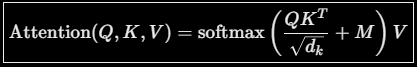 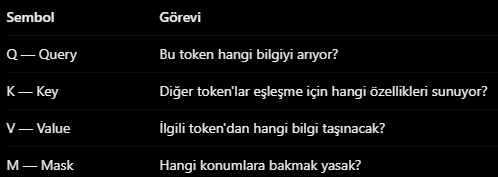

Yukarıdaki ifadeler matematiği daha iyi anlamak için kurulmuş cümleler. Ama şöyle de açıklanabilir:

'Q, K ve V öğrenilebilir doğrusal dönüşümlerle hesaplanan sayısal vektörlerdir.'

Şimdi bizim (vocab_size, 32) boyutunda bir embedding vektörümüz vardı (bknz. sherlockGPT_biagram_language_model.ipynb). Bu da her token yani karakter için 32 boyutlu bir vektör oluşturuyor demekti.

Biraz işi basitleştirmek için diyelim ki input tensor'ümüz 3 tokenlı. Yani

* X = [3*32] lik bir vektör oldu